# Fase 2 · Explore: análisis exploratorio de datos

En esta fase se examina el dataset construido en la fase Sample antes de transformarlo. Interesa saber cuántos ejemplos hay de cada categoría, si las clases están equilibradas, cómo se reparten los lenguajes, qué aspecto tienen los fragmentos y si hay problemas de calidad que el preprocesamiento deba corregir.

Los gráficos se guardan en `reports/figures/`.

In [1]:
import re
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(Path.cwd()))

import estilo
from vulnminer.catalogo import API_2023, NO_EVALUADAS, OWASP_2025
from vulnminer.features import NOMBRES_INDICADORES, extraer_indicadores, limpiar_codigo, tokenizar_codigo

estilo.aplicar()
FIG = RAIZ / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(RAIZ / "data" / "dataset_vulnerabilidades.csv", keep_default_na=False)
df["clase"] = df["vulnerable"].map({1: "Vulnerable", 0: "No vulnerable"})
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1541 entries, 0 to 1540
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   id               1541 non-null   str  
 1   fuente           1541 non-null   str  
 2   proyecto_origen  1541 non-null   str  
 3   archivo_origen   1541 non-null   str  
 4   lenguaje         1541 non-null   str  
 5   tipo_archivo     1541 non-null   str  
 6   framework        1541 non-null   str  
 7   categoria_vuln   1541 non-null   str  
 8   cwe              1541 non-null   str  
 9   vulnerable       1541 non-null   int64
 10  owasp2025        1541 non-null   str  
 11  api2023          1541 non-null   str  
 12  grupo            1541 non-null   str  
 13  particion        1541 non-null   str  
 14  n_lineas         1541 non-null   int64
 15  sha256           1541 non-null   str  
 16  codigo           1541 non-null   str  
 17  clase            1541 non-null   str  
dtypes: int64(2), str(16

## 1. Registros y distribución por categoría OWASP

Un registro vulnerable siempre tiene una categoría de OWASP Top 10:2025 y, si el riesgo también es propio de APIs, una de OWASP API Security Top 10:2023. El gráfico muestra cuántos ejemplos vulnerables respaldan cada una de las veinte categorías.

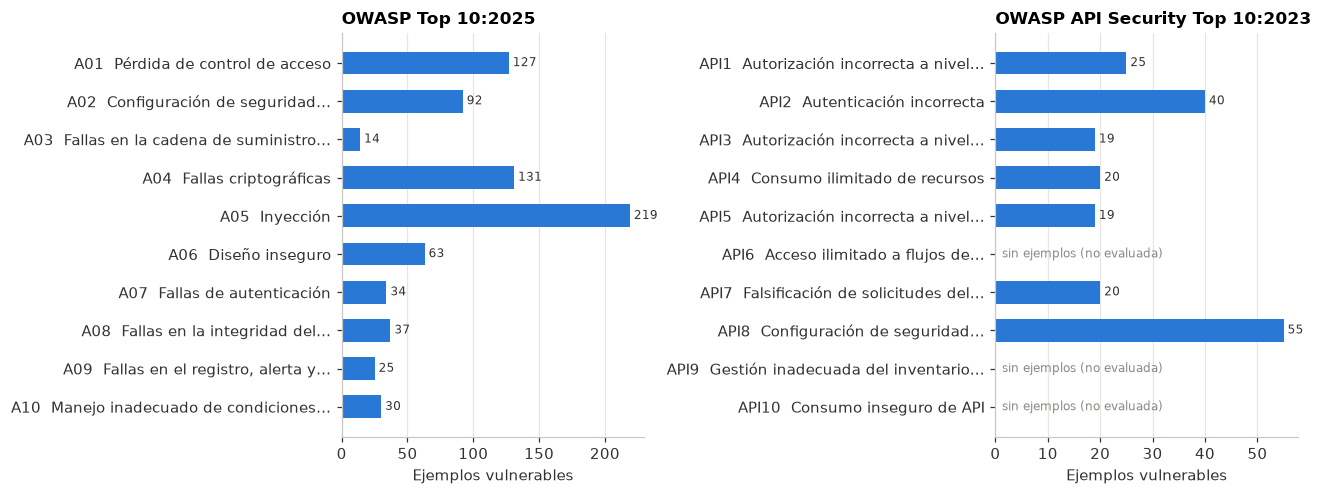

,A01:2025,A02:2025,A03:2025,A04:2025,A05:2025,A06:2025,A07:2025,A08:2025,A09:2025,A10:2025,API1:2023,API2:2023,API3:2023,API4:2023,API5:2023,API6:2023,API7:2023,API8:2023,API9:2023,API10:2023
ejemplos,127,92,14,131,219,63,34,37,25,30,25,40,19,20,19,0,20,55,0,0


In [2]:
vuln = df[df.vulnerable == 1]
conteo_2025 = vuln.owasp2025.value_counts().reindex(list(OWASP_2025), fill_value=0)
conteo_api = vuln.api2023[vuln.api2023 != ""].value_counts().reindex(list(API_2023), fill_value=0)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, conteo, catalogo, titulo in [
    (ejes[0], conteo_2025, OWASP_2025, "OWASP Top 10:2025"),
    (ejes[1], conteo_api, API_2023, "OWASP API Security Top 10:2023"),
]:
    etiquetas = [f"{k.split(':')[0]}  {textwrap.shorten(v, 34, placeholder='…')}" for k, v in catalogo.items()]
    barras = ax.barh(etiquetas[::-1], conteo.values[::-1], color=estilo.AZUL, height=0.6)
    estilo.etiquetar_barras(ax, barras)
    for i, k in enumerate(list(catalogo)[::-1]):
        if k in NO_EVALUADAS:
            ax.text(0.5, i, " sin ejemplos (no evaluada)", va="center", fontsize=8, color=estilo.GRIS)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("Ejemplos vulnerables")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "01_distribucion_owasp.png")
plt.show()

pd.DataFrame({"ejemplos": pd.concat([conteo_2025, conteo_api])}).T

La categoría más representada es A05 Inyección, porque OWASP Benchmark dedica la mayor parte de sus casos a inyección SQL, de comandos, LDAP, XPath, de código y XSS. Le siguen A04 Fallas criptográficas y A01 Pérdida de control de acceso, esta última alimentada tanto por Benchmark (path traversal, redirecciones) como por los casos controlados de BOLA, BFLA y SSRF. En el otro extremo, A03 Cadena de suministro tiene solo 14 ejemplos, todos archivos de dependencias.

En el estándar de APIs la cobertura es más pareja pero también más pequeña, entre 19 y 55 ejemplos por categoría, ya que todos provienen de los casos controlados. API6, API9 y API10 no tienen ejemplos y quedan declaradas como no evaluadas.

## 2. Proporción de ejemplos vulnerables y no vulnerables

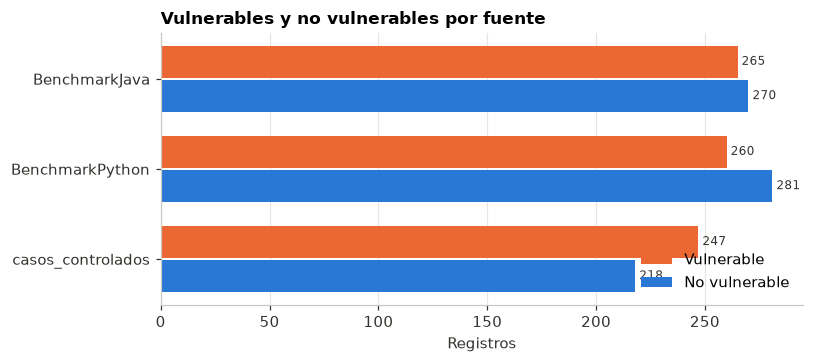

clase
Vulnerable       772
No vulnerable    769
Proporción vulnerable: 0.501


In [3]:
tabla = pd.crosstab(df.proyecto_origen, df.clase)[["Vulnerable", "No vulnerable"]]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
y = np.arange(len(tabla))
alto = 0.36
b1 = ax.barh(y - alto / 2 - 0.01, tabla["Vulnerable"], height=alto, color=estilo.NARANJA, label="Vulnerable")
b2 = ax.barh(y + alto / 2 + 0.01, tabla["No vulnerable"], height=alto, color=estilo.AZUL, label="No vulnerable")
estilo.etiquetar_barras(ax, b1)
estilo.etiquetar_barras(ax, b2)
ax.set_yticks(y, tabla.index)
ax.invert_yaxis()
ax.set_xlabel("Registros")
ax.set_title("Vulnerables y no vulnerables por fuente", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "02_vulnerable_vs_no_vulnerable.png")
plt.show()

print(df.clase.value_counts().to_string())
print(f"Proporción vulnerable: {df.vulnerable.mean():.3f}")

A nivel binario el dataset está prácticamente equilibrado (772 frente a 769) y también lo está dentro de cada fuente. Esto es deliberado: el muestreo por estratos tomó la misma cantidad de casos verdaderos y falsos de cada categoría de Benchmark, y cada plantilla controlada vulnerable tiene su versión corregida. Un equilibrio así evita que el modelo gane exactitud simplemente prediciendo la clase mayoritaria.

## 3. Categorías con mayor y menor representación

El balance binario global esconde un desbalance importante entre categorías. La tabla compara la categoría más y menos frecuente de cada estándar y calcula la razón entre ambas.

In [4]:
def extremos(conteo):
    conteo = conteo[conteo > 0]
    return pd.Series({"mayor": f"{conteo.idxmax()} ({conteo.max()})",
                      "menor": f"{conteo.idxmin()} ({conteo.min()})",
                      "razon_desbalance": round(conteo.max() / conteo.min(), 1)})

pd.DataFrame({"OWASP 2025": extremos(conteo_2025), "API 2023": extremos(conteo_api)})

,OWASP 2025,API 2023
mayor,A05:2025 (219),API8:2023 (55)
menor,A03:2025 (14),API3:2023 (19)
razon_desbalance,15.6,2.9


A05 tiene unas 16 veces más ejemplos que A03. Con una diferencia así, un clasificador multietiqueta tiende a predecir bien las categorías grandes y a ignorar las pequeñas, y la exactitud global lo ocultaría. Por eso en la fase Model conviene usar pesos por clase y en Assess reportar F1 macro y métricas por categoría, que tratan a todas las categorías por igual. En la fase Modify se aplica además un sobremuestreo de los estratos más pequeños del conjunto de entrenamiento.

## 4. Distribución por lenguaje y tipo de archivo

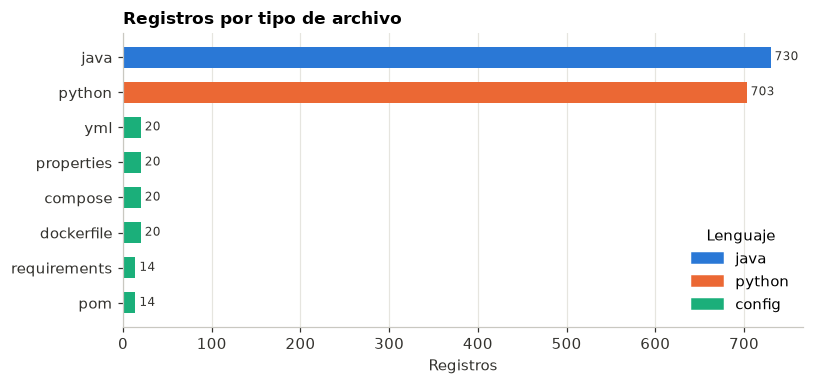

clase,No vulnerable,Vulnerable,total
lenguaje,,,
config,54,54,108
java,360,370,730
python,355,348,703
total,769,772,1541


In [5]:
tipos = df.groupby(["lenguaje", "tipo_archivo"]).size().sort_values()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
colores = {"java": estilo.AZUL, "python": estilo.NARANJA, "config": estilo.AGUA}
etiquetas = [f"{t}" for (_, t) in tipos.index]
barras = ax.barh(etiquetas, tipos.values, color=[colores[l] for (l, _) in tipos.index], height=0.6)
estilo.etiquetar_barras(ax, barras)
ax.set_xlabel("Registros")
ax.set_title("Registros por tipo de archivo", loc="left")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=l) for l, c in colores.items()], loc="lower right", title="Lenguaje")
fig.tight_layout()
fig.savefig(FIG / "03_distribucion_lenguaje.png")
plt.show()

pd.crosstab(df.lenguaje, df.clase, margins=True, margins_name="total")

Java y Python aportan casi la misma cantidad de registros (730 y 703), lo que cumple el requisito de soportar al menos dos lenguajes con un peso similar. Los archivos de configuración son solo 108, repartidos en seis formatos; es poco para que el modelo aprenda cada formato por separado, pero suficiente para que el bloque de indicadores de configuración (CORS abierto, modo debug, contenedor como root) tenga ejemplos positivos y negativos.

## 5. Características de los fragmentos de código

### Longitud

                   count   mean   std   min   25%    50%    75%    max
proyecto_origen                                                       
BenchmarkJava      535.0  105.7  25.5  57.0  86.0  104.0  124.5  199.0
BenchmarkPython    541.0   63.2   8.7  43.0  56.0   65.0   70.0   90.0
casos_controlados  465.0   14.7   4.2   5.0  13.0   15.0   17.0   24.0


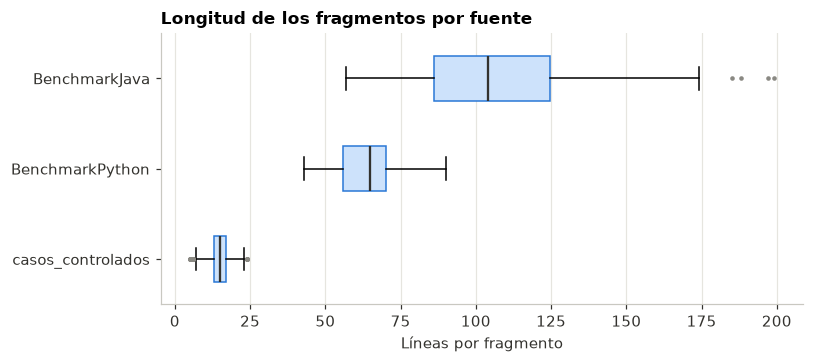

In [6]:
print(df.groupby("proyecto_origen")["n_lineas"].describe().round(1).to_string())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
orden = ["casos_controlados", "BenchmarkPython", "BenchmarkJava"]
datos = [df.loc[df.proyecto_origen == p, "n_lineas"] for p in orden]
caja = ax.boxplot(datos, orientation="horizontal", tick_labels=orden, widths=0.5, patch_artist=True,
                  medianprops=dict(color=estilo.TEXTO, linewidth=1.5),
                  flierprops=dict(marker="o", markersize=3, markerfacecolor=estilo.GRIS, markeredgecolor="none"))
for parche in caja["boxes"]:
    parche.set(facecolor="#cde2fb", edgecolor=estilo.AZUL)
ax.set_xlabel("Líneas por fragmento")
ax.set_title("Longitud de los fragmentos por fuente", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "04_longitud_fragmentos.png")
plt.show()

Las tres fuentes tienen longitudes muy distintas: los casos controlados rondan las 15 líneas, Benchmark Python las 63 y Benchmark Java las 106. La longitud, por lo tanto, delata la fuente. Dentro de Benchmark los vulnerables y los no vulnerables tienen tamaños parecidos, pero en los casos controlados la versión corregida suele tener entre 2 y 4 líneas más, porque la corrección añade código (comprobar el propietario, limitar el tamaño de página, registrar el evento). Si el modelo recibiera la longitud, podría aprender que "más largo es más seguro", una regla sin sentido fuera de este dataset. Por eso la longitud se usa solo en este análisis y no se incluye entre las características del modelo.

In [7]:
df.groupby(["proyecto_origen", "clase"])["n_lineas"].median().unstack()

clase,No vulnerable,Vulnerable
proyecto_origen,,
BenchmarkJava,105.0,103.0
BenchmarkPython,65.0,64.0
casos_controlados,16.5,14.0


### Estructuras y patrones frecuentes

Para ver qué patrones distinguen el código vulnerable del seguro se calcularon, sobre el código ya limpio de comentarios, los indicadores de seguridad que se usarán en la fase Modify (por ejemplo, consultas SQL construidas por concatenación, uso de algoritmos criptográficos débiles, comprobaciones de rol o propietario, validación de entrada, excepciones expuestas). El gráfico muestra los indicadores cuya frecuencia más cambia entre ambas clases.

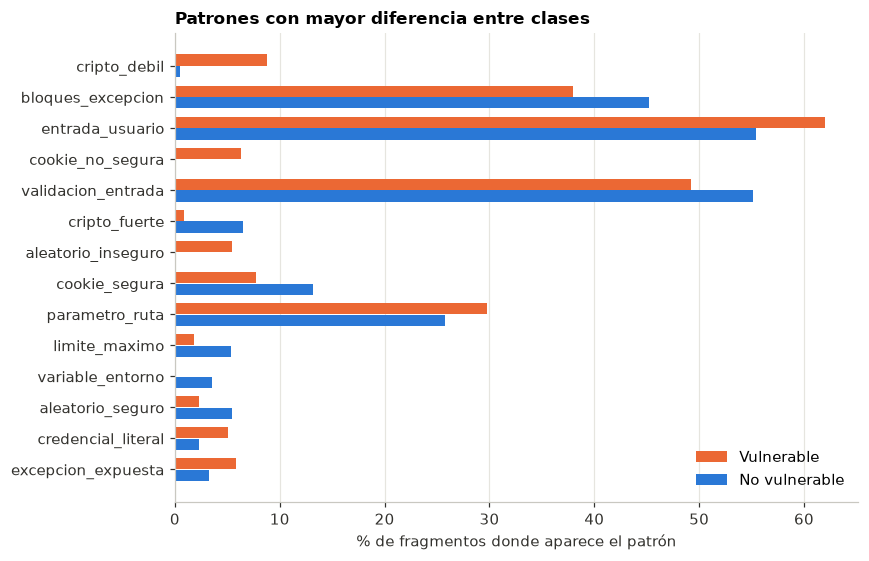

clase,No vulnerable,Vulnerable,diferencia
cripto_debil,0.5,8.8,8.3
bloques_excepcion,45.3,38.0,-7.3
entrada_usuario,55.4,62.0,6.7
cookie_no_segura,0.0,6.3,6.3
validacion_entrada,55.1,49.2,-5.9
cripto_fuerte,6.5,0.9,-5.6
aleatorio_inseguro,0.0,5.4,5.4
cookie_segura,13.1,7.8,-5.4
parametro_ruta,25.7,29.8,4.0
limite_maximo,5.3,1.8,-3.5


In [8]:
limpio = [limpiar_codigo(c, t) for c, t in zip(df.codigo, df.tipo_archivo)]
ind = pd.DataFrame([extraer_indicadores(t) for t in limpio], columns=NOMBRES_INDICADORES)
activo = ind > 0
frecuencia = activo.groupby(df.clase).mean().T * 100
frecuencia["diferencia"] = frecuencia["Vulnerable"] - frecuencia["No vulnerable"]
top = frecuencia.reindex(frecuencia.diferencia.abs().sort_values(ascending=False).index).head(14)
top = top.iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.2))
y = np.arange(len(top))
alto = 0.36
ax.barh(y + alto / 2 + 0.01, top["Vulnerable"], height=alto, color=estilo.NARANJA, label="Vulnerable")
ax.barh(y - alto / 2 - 0.01, top["No vulnerable"], height=alto, color=estilo.AZUL, label="No vulnerable")
ax.set_yticks(y, top.index)
ax.set_xlabel("% de fragmentos donde aparece el patrón")
ax.set_title("Patrones con mayor diferencia entre clases", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "05_frecuencia_patrones.png")
plt.show()

top.iloc[::-1].round(1)

Los patrones que más separan las clases tienen una lectura de seguridad directa. En los fragmentos vulnerables aparecen con más frecuencia algoritmos débiles como MD5, SHA-1 o DES, cookies sin el atributo `secure`, aleatoriedad no criptográfica, credenciales escritas en el código y excepciones devueltas al cliente. En los no vulnerables aparecen más las funciones criptográficas robustas, `SecureRandom` o `secrets`, la validación de entradas, los límites de tamaño de página y la lectura de secretos desde variables de entorno.

Las diferencias son de pocos puntos porcentuales porque cada patrón corresponde a una sola categoría: por ejemplo, el uso de criptografía débil solo es relevante en el 7 % del dataset que trata de cifrado y hashing. Además, ningún patrón por sí solo separa las clases. Esto es especialmente claro en Benchmark, donde muchos casos seguros contienen la misma llamada peligrosa que los vulnerables, pero el dato del usuario nunca llega a ella por una condición del flujo de control. Esa es la razón para combinar estos indicadores con una representación más rica del código (TF-IDF) y dejar que un modelo aprenda cómo se combinan, en lugar de usar los indicadores como reglas.

In [9]:
def tokens_frecuentes(textos, n=15):
    conteo = pd.Series([t for x in textos for t in set(tokenizar_codigo(x)) if len(t) > 2]).value_counts()
    return conteo.head(n)

pd.DataFrame({
    "controlados_vulnerables": tokens_frecuentes([t for t, (p, v) in zip(limpio, zip(df.proyecto_origen, df.vulnerable)) if p == "casos_controlados" and v == 1]).index,
    "controlados_seguros": tokens_frecuentes([t for t, (p, v) in zip(limpio, zip(df.proyecto_origen, df.vulnerable)) if p == "casos_controlados" and v == 0]).index,
})

,controlados_vulnerables,controlados_seguros
0,return,get
1,api,return
2,get,NUM
3,example,api
4,service,com
5,com,example
6,class,service
7,public,class
8,package,user
9,NUM,public


Los tokens más frecuentes son casi los mismos en ambas clases y corresponden a la estructura común de los frameworks y de las plantillas (`return`, `class`, `public`, `import`, `api`, `service`). Contar palabras sueltas no basta para distinguir código seguro de inseguro. TF-IDF reduce automáticamente el peso de estos términos, que aparecen en casi todos los documentos, y los bigramas permiten captar combinaciones con más significado.

## 6. Duplicados, valores faltantes e inconsistencias

In [10]:
print("Duplicados exactos de código:", df.sha256.duplicated().sum())
print("Duplicados de id:", df.id.duplicated().sum())

limpio_norm = pd.Series([" ".join(t.split()) for t in limpio])
print("Duplicados tras quitar comentarios y espacios:", limpio_norm.duplicated().sum())

faltantes = (df.drop(columns="clase") == "").sum()
print("\nCampos vacíos por columna:")
print(faltantes[faltantes > 0].to_string())

inconsistentes = ((df.vulnerable == 1) & (df.owasp2025 == "")) | ((df.vulnerable == 0) & (df.owasp2025 != ""))
print("\nEtiquetas inconsistentes (vulnerable sin categoría o seguro con categoría):", inconsistentes.sum())

Duplicados exactos de código: 0
Duplicados de id: 0
Duplicados tras quitar comentarios y espacios: 0

Campos vacíos por columna:
owasp2025     769
api2023      1343

Etiquetas inconsistentes (vulnerable sin categoría o seguro con categoría): 0


No hay duplicados ni identificadores repetidos. Los únicos campos vacíos son `owasp2025` y `api2023`, y son vacíos esperados: los 769 registros no vulnerables no llevan categoría, y entre los vulnerables solo los riesgos que también son de API tienen etiqueta del segundo estándar. No hay etiquetas contradictorias.

Sí apareció un problema de calidad más sutil al leer el código: algunos datos revelan la etiqueta sin tener nada que ver con la vulnerabilidad.

In [11]:
patron_fuga = r"(?:cmdi|crypto|hash|ldapi|pathtraver|securecookie|sqli|trustbound|weakrand|xpathi|xss|codeinj|deserialization|redirect|xxe)-\d\d"
con_fuga = df.codigo.str.contains(patron_fuga)
con_licencia = df.codigo.str.contains("GNU General Public License")
con_comentario = (df.proyecto_origen == "casos_controlados") & df.codigo.str.contains(r"//\s|#\s")
pd.DataFrame({
    "nombre de categoría en rutas": con_fuga.groupby(df.proyecto_origen).sum(),
    "cabecera de licencia": con_licencia.groupby(df.proyecto_origen).sum(),
    "comentarios explicativos": con_comentario.groupby(df.proyecto_origen).sum(),
})

,nombre de categoría en rutas,cabecera de licencia,comentarios explicativos
proyecto_origen,,,
BenchmarkJava,535,535,0
BenchmarkPython,541,541,0
casos_controlados,0,0,10


In [12]:
ejemplo = df[(df.proyecto_origen == "BenchmarkJava")].iloc[0].codigo
print("\n".join(l for l in ejemplo.splitlines() if re.search(patron_fuga, l)))

@WebServlet(value = "/ldapi-00/BenchmarkTest00012")


Todos los casos de Benchmark incluyen en sus rutas el nombre de su categoría (por ejemplo `/sqli-00/BenchmarkTest00012`) y un identificador numérico único. Si esto llega al modelo, aprenderá a leer la palabra `sqli` en la URL en lugar del patrón de inyección, y el resultado no servirá para código real. También traen una cabecera de licencia idéntica en todos los archivos, y algunos casos controlados tienen comentarios que explican el problema. 

Hay además una fuga menos evidente. Para que un caso sea seguro, Benchmark suele hacer que el dato del usuario se reemplace por una cadena fija en una rama del código, y para eso usa siempre las mismas cadenas de relleno. La siguiente tabla muestra los literales de Benchmark que aparecen en al menos 15 casos y cuya presencia está fuertemente asociada a una de las clases.

In [13]:
literal = re.compile(r'"([^"\n]{2,60})"|\'([^\'\n]{2,60})\'')
bench = df[df.proyecto_origen != "casos_controlados"]
conteo = {}
for codigo, v in zip(bench.codigo, bench.vulnerable):
    for lit in {a or c for a, c in literal.findall(codigo)}:
        conteo.setdefault(lit, [0, 0])[v] += 1
lits = pd.DataFrame([(l, n0, n1) for l, (n0, n1) in conteo.items() if n0 + n1 >= 15],
                    columns=["literal", "seguros", "vulnerables"])
lits["prop_vulnerable"] = (lits.vulnerables / (lits.seguros + lits.vulnerables)).round(2)
lits[(lits.prop_vulnerable - 0.5).abs() > 0.3].sort_values("prop_vulnerable")

,literal,seguros,vulnerables,prop_vulnerable
16,' and secure flag set to: true,25,0,0.00
68,SHA1PRNG,25,0,0.00
139,) or not bar.endswith(,18,0,0.00
93,AES,21,0,0.00
140,) or,18,0,0.00
69,another_Value,29,3,0.09
80,bob's your uncle,27,3,0.10
70,a_Value,56,8,0.12
43,This_should_always_happen,99,15,0.13
152,text,21,5,0.19


La tabla mezcla dos tipos de literales. Algunos son información de seguridad legítima: `DES` es un algoritmo débil y `AES` o `SHA1PRNG` son opciones seguras, así que es correcto que el modelo los asocie con una clase. Otros son relleno sin ningún significado (`This_should_always_happen`, `bobs_your_uncle`, `a_Value`, `alsosafe`) o mensajes que repiten la etiqueta (`secure flag set to: false`). Un modelo que aprendiera estos últimos obtendría buenas métricas en Benchmark y no detectaría nada en un proyecto real. A esa lista se suman `safe` y `moresafe`, que Benchmark mete en listas auxiliares y que también aparecen con más frecuencia en los casos seguros.

Todas las fugas de este apartado se corrigen en la fase Modify: se eliminan los comentarios y licencias, se reemplazan los nombres de categoría e identificadores, y los literales de relleno y los mensajes que repiten la etiqueta se sustituyen por un valor neutro.

## 7. Desbalance entre clases

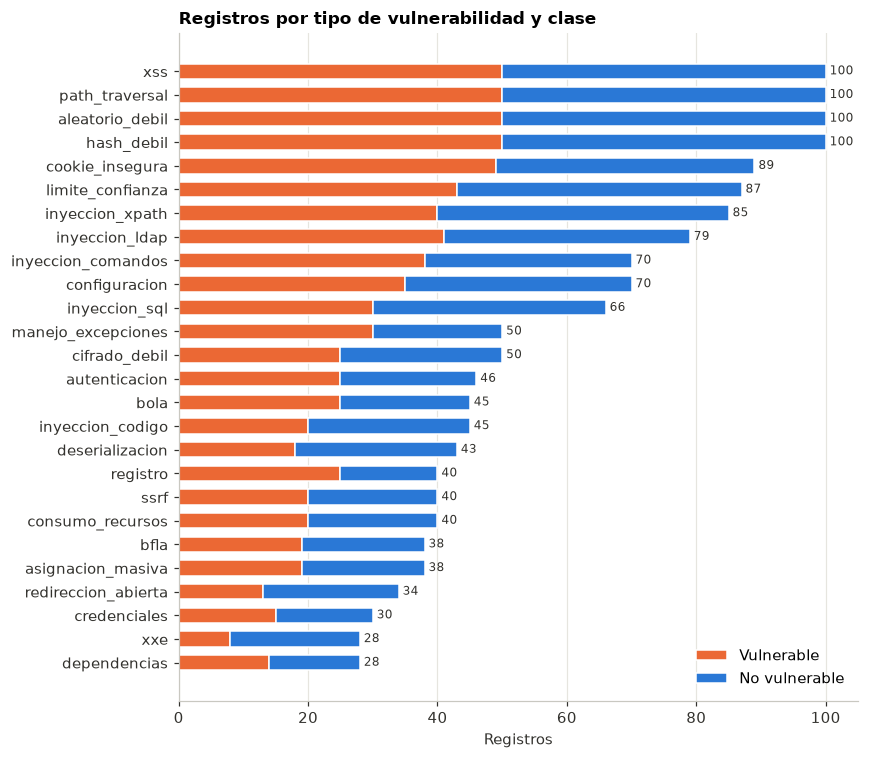

Etiquetas con ejemplos: 17; mínimo 14, mediana 34, máximo 219


In [14]:
estratos = pd.crosstab(df.categoria_vuln, df.clase)[["Vulnerable", "No vulnerable"]]
estratos = estratos.loc[estratos.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(estratos))
ax.barh(y, estratos["Vulnerable"], height=0.65, color=estilo.NARANJA, label="Vulnerable",
        edgecolor="white", linewidth=1)
ax.barh(y, estratos["No vulnerable"], left=estratos["Vulnerable"], height=0.65, color=estilo.AZUL,
        label="No vulnerable", edgecolor="white", linewidth=1)
for i, total in enumerate(estratos.sum(axis=1)):
    ax.text(total, i, f" {total}", va="center", fontsize=8, color=estilo.TEXTO)
ax.set_yticks(y, estratos.index)
ax.set_xlabel("Registros")
ax.set_title("Registros por tipo de vulnerabilidad y clase", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "06_desbalance_clases.png")
plt.show()

conteo_etiquetas = pd.concat([conteo_2025, conteo_api[conteo_api > 0]])
print(f"Etiquetas con ejemplos: {len(conteo_etiquetas)}; mínimo {conteo_etiquetas.min()}, "
      f"mediana {conteo_etiquetas.median():.0f}, máximo {conteo_etiquetas.max()}")

Dentro de cada tipo de vulnerabilidad las dos clases están razonablemente equilibradas, pero entre tipos hay diferencias grandes: van de 28 registros (XXE y dependencias) a 100 (XSS, path traversal, hashing y aleatoriedad débiles). Como cada tipo alimenta una etiqueta OWASP distinta, el desbalance relevante para el modelo es el de etiquetas, que va de 14 a 219 ejemplos.

## Conclusiones sobre la calidad y representatividad del dataset

El dataset es adecuado para entrenar un primer modelo: tiene un tamaño suficiente, etiquetas trazables a un CWE, clases binarias equilibradas y dos lenguajes con peso similar. También cubre los tipos de archivo que aparecen en un proyecto de microservicios real.

Sus limitaciones son claras y conviene tenerlas presentes en las fases siguientes. La cobertura por categoría está desbalanceada, con A05 muy por encima de A03, A09 o A10. Las tres fuentes difieren en estilo y longitud, así que existe el riesgo de que el modelo aprenda a reconocer la fuente en vez de la vulnerabilidad. Además, los casos controlados son variaciones de pocas plantillas escritas por el equipo, por lo que representan bien los patrones elegidos pero no toda la variedad de código que se encontrará en un proyecto real. Y en Benchmark muchos casos seguros solo se distinguen de los vulnerables por el flujo de datos, algo difícil de capturar con representaciones basadas en tokens.

De este análisis salen cuatro decisiones para la fase Modify: eliminar las fugas de etiqueta (nombres de categoría, identificadores, licencias, comentarios y literales de relleno), excluir la longitud de las características del modelo, representar el código combinando TF-IDF con indicadores de seguridad y el tipo de archivo, y tratar el desbalance entre categorías en el conjunto de entrenamiento.